# K-Nearest Neighbors Workshop Solution

This notebook follows the peer-programming exercise through Steps 1–4: acquire data, preprocess it, implement KNN using the workshop pipeline, and evaluate the model. Step 5 (comparing results with peers) is intentionally omitted.

## Dataset choice

The supplied API is [Frankfurter](https://api.frankfurter.dev/). I selected six months of daily exchange-rate records for seven base currencies. Each row contains rates to common quote currencies. The model predicts the USD exchange rate from the remaining exchange-rate features, making this a KNN regression task.

## Step 1: Acquire data

The API returns daily historical rates for a requested base currency. The loop below retrieves the preceding 183 days for every selected base currency, keeps the same six quote currencies, and combines the records into one table.

In [2]:
from datetime import date, timedelta

import requests
import pandas as pd

url = "https://api.frankfurter.dev/v1"
base_currencies = ["EUR", "GBP", "CHF", "USD", "CAD", "AUD", "JPY"]
quote_currencies = ["USD", "GBP", "CHF", "CAD", "AUD", "JPY"]
end_date = date.today()
start_date = end_date - timedelta(days=183)

records = []
for base_currency in base_currencies:
    response = requests.get(
        f"{url}/{start_date.isoformat()}..{end_date.isoformat()}",
        params={
            "base": base_currency,
            "symbols": ",".join(quote_currencies),
        },
        timeout=30,
    )
    response.raise_for_status()
    api_response = response.json()
    for record_date, rates in api_response["rates"].items():
        record = {"base_currency": api_response["base"], "date": record_date}
        record.update(rates)
        records.append(record)

df = pd.DataFrame(records)
print(f"Retrieved {len(df)} records from {start_date} through {end_date}.")
df.head()

Retrieved 917 records from 2026-04-09 through 2026-10-09.


,base_currency,date,AUD,CAD,CHF,GBP,JPY,USD
0,EUR,2026-04-09,1.6593,1.6175,0.9240,0.87053,185.70,1.1685
1,EUR,2026-04-10,1.6561,1.6187,0.9241,0.87105,186.43,1.1711
2,EUR,2026-04-13,1.6610,1.6177,0.9242,0.87058,186.75,1.1684
3,EUR,2026-04-14,1.6558,1.6225,0.9210,0.86913,187.33,1.1793
4,EUR,2026-04-15,1.6507,1.6235,0.9220,0.86935,187.41,1.1780


## Step 2: Preprocess data

The base currency is retained as an identifier and is not used as a numerical feature. USD is the numerical target, so it is excluded from the features. Rows without a USD rate are removed, missing feature values are imputed with the training-set median, and the features are standardized using training data only so that large-valued rates do not dominate Euclidean distance or leak information from the test set.

In [3]:
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

target_column = "USD"
feature_columns = [currency for currency in quote_currencies if currency != target_column]
X = df[feature_columns].apply(pd.to_numeric, errors="coerce")
y = pd.to_numeric(df[target_column], errors="coerce")
valid_rows = y.notna()
X = X.loc[valid_rows]
y = y.loc[valid_rows]

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42
)

imputer = SimpleImputer(strategy="median")
X_train_imputed = imputer.fit_transform(X_train_raw)
X_test_imputed = imputer.transform(X_test_raw)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_imputed)
X_test = scaler.transform(X_test_imputed)

print("Missing values before imputation:")
print(X.isna().sum())
print("\nPrepared training and testing shapes:", X_train.shape, X_test.shape)

Missing values before imputation:
GBP    131
CHF    131
CAD    131
AUD    131
JPY    131
dtype: int64

Prepared training and testing shapes: (550, 5) (236, 5)


## Step 3: Implement KNN using the pipeline sequence

The data was split into training and testing sets during preprocessing, then the imputer and scaler were fit on the training data only. A KNN regressor is now fitted with `k=3` using the standardized features.

In [4]:
from sklearn.neighbors import KNeighborsRegressor

knn = KNeighborsRegressor(n_neighbors=3, metric="euclidean")
knn.fit(X_train, y_train)

,n_neighbors,3
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'euclidean'
,metric_params,None
,n_jobs,None


## Step 4: Train and evaluate KNN

Mean absolute error, root mean squared error, and R-squared summarize predictions for exchange-rate records that were not used during fitting. The scatter plot shows the raw USD exchange-rate data, with each base currency represented by a different color.

Mean absolute error: 0.0035976412429378534
Root mean squared error: 0.00560577415775209
R-squared: 0.999844197936818


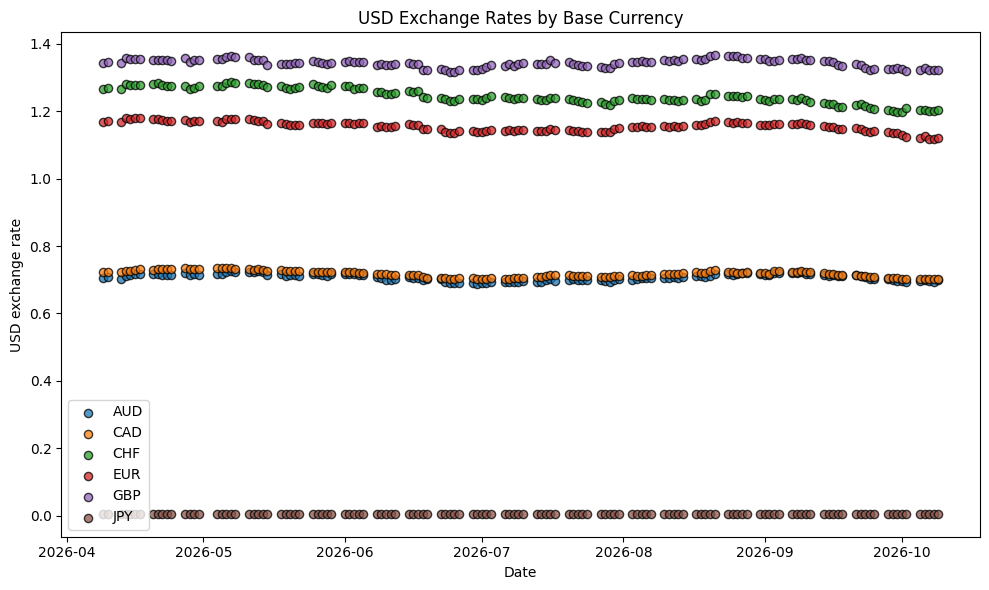

In [5]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import matplotlib.pyplot as plt

y_pred = knn.predict(X_test)
print("Mean absolute error:", mean_absolute_error(y_test, y_pred))
print("Root mean squared error:", mean_squared_error(y_test, y_pred) ** 0.5)
print("R-squared:", r2_score(y_test, y_pred))

plt.figure(figsize=(10, 6))
for base_currency, group in df.dropna(subset=["USD"]).groupby("base_currency"):
    plt.scatter(
        pd.to_datetime(group["date"]),
        group["USD"],
        label=base_currency,
        alpha=0.75,
        edgecolor="black",
        s=35,
    )
plt.xlabel("Date")
plt.ylabel("USD exchange rate")
plt.title("USD Exchange Rates by Base Currency")
plt.legend()
plt.tight_layout()
plt.show()

## Reflection

KNN is appropriate for this experiment because it can estimate a new USD rate from similar standardized exchange-rate profiles. Scaling is especially important because the features use different numeric ranges. The result should be interpreted cautiously: although the six-month history provides many more observations, the records come from a small, hand-selected currency subset. This remains a demonstration of the workflow rather than a production currency forecasting model. A larger historical dataset and repeated validation would be needed for a reliable conclusion.

# Pair Team Evaluation
## Group 6 observing Group 1
blabla